# Designed in KLayout (or code) → LOM netlist → lumped-circuit simulation

Use this notebook when a chip was drawn with the Quantcore KLayout plugin (or in code) and you want to simulate its
**lumped circuit** without, or before, a full-wave run:

1. **Get the netlist:**
   - in KLayout: *Quantcore ▸ Export LOM circuit* writes `build/<design>.circuit.json`;
   - from a terminal: `qcc circuit export design.json`.
2. **Simulate it:** QuCat gives the normal modes and κ; the QuTiP-diagonalised circuit Hamiltonian gives the
   dressed f_q, α, f_r and χ.
3. **Explore:** sweep an element (here Lj and C_g) to see where the targets are.
4. **Optionally fill it with FEM** (HFSS/Q3D/Sonnet results) and compare with the estimates.
5. **LOM → layout:** go the other way, from targets to a laid-out chip, live in KLayout.

**`KLAYOUT_GUI`** (next to `LIVE`): `True` opens the KLayout window when it is not running (≈ 15–20 s the first time, with the layout and the Quantcore plugin), reopens it if you closed it, and brings it to the front on the first build; `False` only redraws a KLayout you already have open (klive).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
os.chdir(ROOT)                                   # paths below are relative to the repo root

import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

import quantcore_circuits as qcc
from quantcore_circuits import loop, plots
from quantcore_circuits.designer import Designer
from quantcore_circuits.live.snapshot import gui_snapshot, snapshot
from quantcore_circuits.track import Run

usetex = plots.use_style()                       # plot-guidelines style
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
KLAYOUT_GUI = True                               # True: open / raise the KLayout window; False: redraw an open one only
from quantcore_circuits.live.klayout import use_gui
use_gui(KLAYOUT_GUI)
from quantcore_circuits import track
TRACKING = track.start("lom_from_layout")       # dashboard: records into build/lom_from_layout (scripts\dashboard.cmd)

from quantcore_circuits.circuit.schema import load_circuit, save_circuit
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.lom import lom_from_design

CIRCUIT = Path("build/q1_r1_feedline.circuit.json")      # what the KLayout plugin's "Export LOM circuit" writes
if not CIRCUIT.exists():                                  # or export it here from any design
    save_circuit(lom_from_design("examples/q1_r1_feedline.json").model, CIRCUIT)
model = load_circuit(CIRCUIT)
display(Markdown("| node | FEM nets |\n|---|---|\n" + "\n".join(
    f"| {n} | {'ground' if s.ground else ', '.join(s.nets)} |" for n, s in model.nodes.items())))
display(Markdown("| element | type | nodes |\n|---|---|---|\n" + "\n".join(
    f"| {n} | {b.type} | {b.nodes[0]} – {b.nodes[1]} |" for n, b in model.branches.items())))

| node | FEM nets |
|---|---|
| gnd | ground |
| FL | FL, PAD_W.pad, PAD_E.pad |
| Q1 | Q1.island |
| Q1.claw_n | Q1.claw_n |

| element | type | nodes |
|---|---|---|
| Port_PAD_W | R | FL – gnd |
| Port_PAD_E | R | FL – gnd |
| C_Q1 | C | Q1 – gnd |
| J_Q1 | SQUID | Q1 – gnd |
| Cg_Q1_claw_n | C | Q1 – Q1.claw_n |
| Cc_Q1_claw_n | C | Q1.claw_n – gnd |
| R1 | TLres | Q1.claw_n – gnd |
| K_R1 | HANGER | Q1.claw_n – FL |

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| Q1 | qubit | 5.5201 | 0.000137 | 278.4 | J_Q1 0.998, R1 0.002 |
| R1 | resonator | 6.7600 | 0.135 | 0.0 | J_Q1 0.002, R1 0.998 |

{'Q1.f_q_GHz': 5.2243, 'Q1.alpha_MHz': -321.0169, 'R1.chi_MHz': -0.9612, 'R1.f_GHz': 6.7594, 'R1.kappa_MHz': 0.1353}


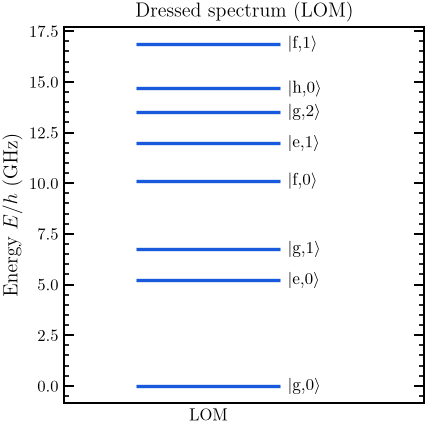

In [2]:
res = simulate(fill(model, None))                        # stand-alone: the circuit's own values
display(Markdown("| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |\n|---|---|---|---|---|---|\n" + "\n".join(
    f"| {m.label} | {m.kind} | {m.f_GHz:.4f} | {m.kappa_MHz:.3g} | {m.anharmonicity_MHz:.1f} | "
    + ", ".join(f"{k} {v:.3f}" for k, v in m.participation.items()) + " |" for m in res.modes)))
print({k: round(v, 4) for k, v in res.params.items()})
fig, ax = plots.figure("square_medium")
plots.plot_spec(plots.levels_spec("lv", "Dressed spectrum (LOM)", "hamiltonian",
                                  [{**lv, "group": "LOM"} for lv in res.dressed["levels"][:8]]), ax)
plt.show()

## Sweep: junction inductance and coupling capacitance

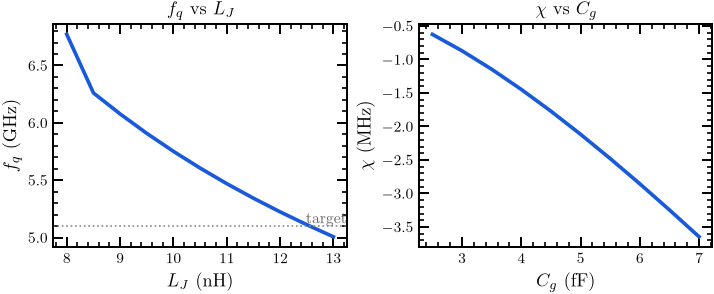

In [3]:
import copy, numpy as np
def with_values(m, **vals):
    m2 = m.model_copy(deep=True)
    for name, v in vals.items():
        key = "Lj_nH" if m2.branches[name].type in ("JJ", "SQUID") else "estimate"
        m2.branches[name].value[key] = v
    return m2

lj = np.linspace(8, 13, 11)
sweep = [simulate(fill(with_values(model, J_Q1=x), None)).params for x in lj]
cg = np.linspace(2.5, 7.0, 10)
sweep_g = [simulate(fill(with_values(model, Cg_Q1_claw_n=x), None)).params for x in cg]
fig, (a1, a2) = plots.figure("two", 1, 2)
plots.plot_spec(plots.xy_spec("lj", "f_q vs L_J", "plots", [{"name": "f_q", "x": lj.tolist(), "y": [p["Q1.f_q_GHz"] for p in sweep]}],
                              "L_J (nH)", "f_q (GHz)", [{"axis": "y", "value": 5.1, "label": "target"}]), a1)
plots.plot_spec(plots.xy_spec("cg", "χ vs C_g", "plots", [{"name": "χ", "x": cg.tolist(), "y": [p["R1.chi_MHz"] for p in sweep_g]}],
                              "C_g (fF)", "χ (MHz)"), a2)
plt.show()

## Fill from a simulation (optional) and compare with the estimates

In [4]:
from quantcore_circuits.circuit.derive import circuit_from_design
JOB = Path("build/jobs/q1_r1_feedline_Q1R1_q3d_cmatrix")
if (JOB / "results" / "results.json").exists():
    filled = fill(circuit_from_design("examples/q1_r1_feedline.json", "Q1R1"), "examples/q1_r1_feedline.json", JOB)
    display(Markdown("| branch | estimate | FEM | Δ |\n|---|---|---|---|\n" + "\n".join(
        f"| {r['branch']} | {r['estimate']:.4g} | {r['extracted']:.4g} | {100 * (r['extracted'] / r['estimate'] - 1):+.1f} % |"
        for r in filled.branch_table() if r['extracted'] is not None and r['estimate'])))
    fem = simulate(filled)
    print("estimates:", {k: round(v, 4) for k, v in res.params.items() if k.startswith("Q1")})
    print("FEM      :", {k: round(v, 4) for k, v in fem.params.items() if k.startswith("Q1")})

| branch | estimate | FEM | Δ |
|---|---|---|---|
| C_Q1 | 64.05 | 64.05 | +0.0 % |
| Cg_Q1_claw_n | 3.17 | 3.173 | +0.1 % |
| Cc_Q1_claw_n | 76.4 | 76.41 | +0.0 % |

estimates: {'Q1.f_q_GHz': 5.2243, 'Q1.alpha_MHz': -321.0169}
FEM      : {'Q1.f_q_GHz': 5.2242, 'Q1.alpha_MHz': -320.993}


## LOM → layout: two qubits from targets, laid out live

[qcc] KLayout: {'started': True, 'pid': 10224, 'klive': True, 'seconds': 4.3}


[qcc] route FL: built in 6.03 s → build\two_qubit.oas
[qcc] add Q1 (Xmon): built in 0.14 s → build\two_qubit.oas


[qcc] route R1: built in 0.17 s → build\two_qubit.oas


[qcc] add PAD_F1 (BondPad): built in 0.12 s → build\two_qubit.oas


[qcc] route FLUX1: built in 0.16 s → build\two_qubit.oas


[qcc] add Q2 (Xmon): built in 0.14 s → build\two_qubit.oas


[qcc] route R2: built in 0.19 s → build\two_qubit.oas


[qcc] add PAD_F2 (BondPad): built in 0.16 s → build\two_qubit.oas


[qcc] route FLUX2: built in 0.17 s → build\two_qubit.oas


{'Q1.cross_length': 416.74, 'Q1.claw_length': 182.31, 'Q1.junction.Lj_nH': 9.28, 'R1.length': 3640.58}
{'Q2.cross_length': 438.48, 'Q2.claw_length': 152.55, 'Q2.junction.Lj_nH': 8.04, 'R2.length': 3562.69}
DRC clean


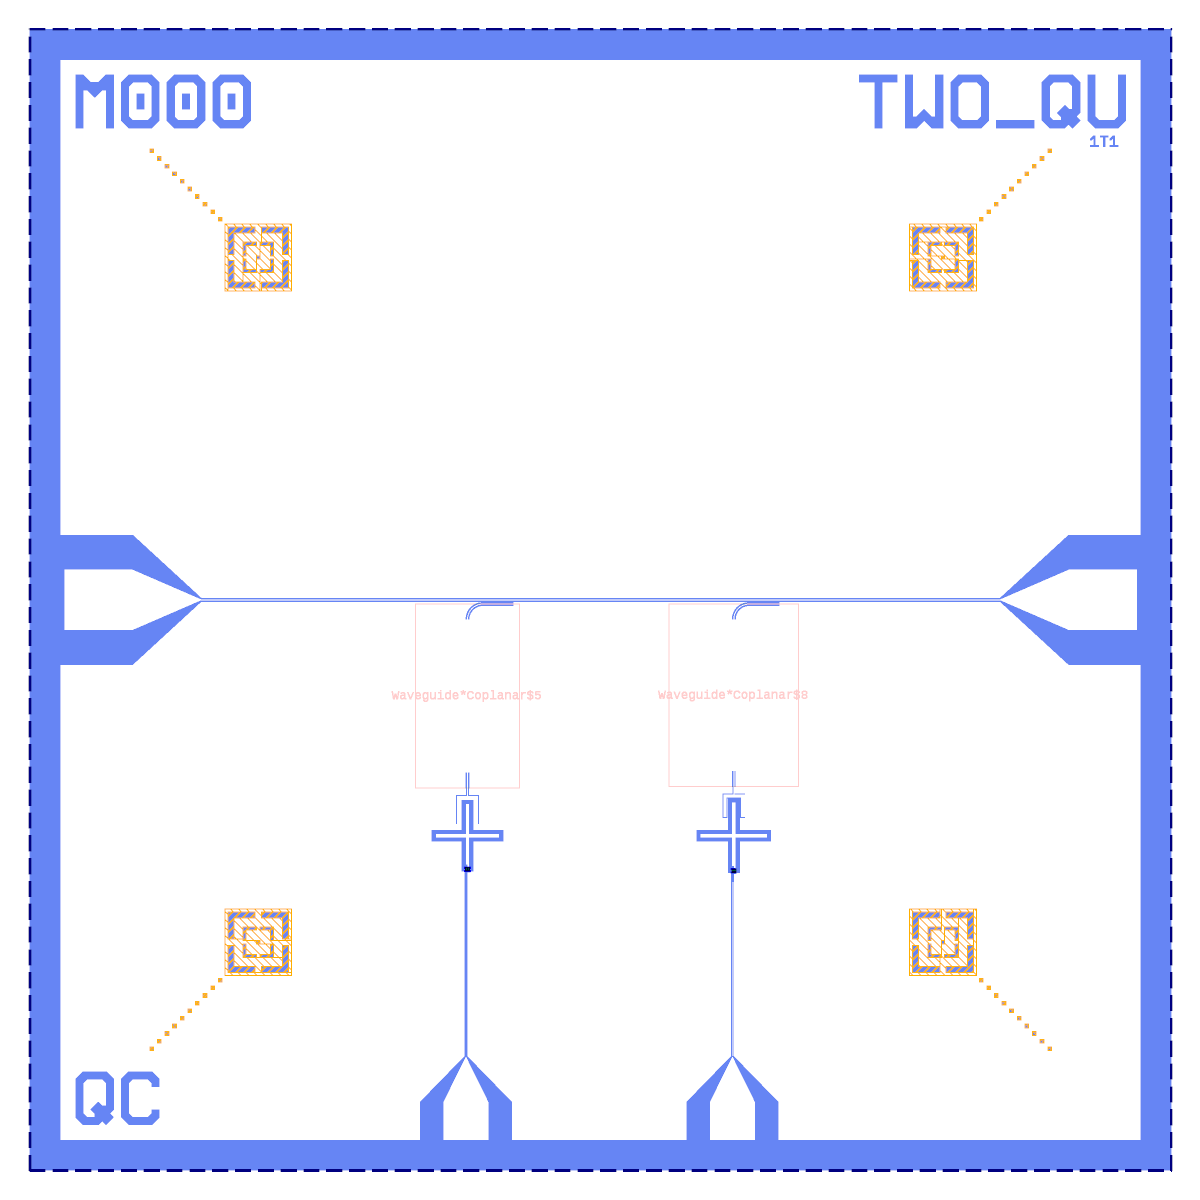

In [5]:
from quantcore_circuits.lom.synthesize import PairTarget, layout_from_targets
d2 = layout_from_targets("two_qubit", [PairTarget("Q1", 5.1, -220, "R1", 7.2, 90),
                                       PairTarget("Q2", 5.4, -210, "R2", 7.5, 80)], live=LIVE, delay=0.3)
for s in d2.synthesis:
    print({k: round(v, 2) for k, v in s["knobs"].items()})
print(d2.drc()); d2.save("examples/two_qubit_synth.json")
if LIVE:
    png, src = gui_snapshot("build/shots/two_qubit.png", (1200, 1200), layout=d2.out)
else:
    d2.show()                                    # build + write the layout (no KLayout)
    png, src = snapshot(d2.out, "build/shots/two_qubit.png", size=(1200, 1200)), "headless"
display(Image(filename=str(png), width=460))